# Linear Regression: Training one Parameter

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# The class for plotting
import torch


class plot_diagram():

    # Constructor
    def __init__(self, x, y,w,stop,go=False):
        start = w.data
        self.error = []
        self.parameter = []
        print(type(x.numpy()))
        self.x = x.numpy()
        self.y = y.numpy()
        self.param_values = torch.arange(start, stop)
        self.Loss_function = [criterion(forward(x),y) for w.data in self.param_values]
        w.data = start

    # Executor
    def __call__(self,yhat,w,error,n):
        self.error.append(error)
        self.parameter.append(w.data)
        plt.subplot(212)
        plt.plot(self.x,yhat.detach().numpy())
        plt.plot(self.x,self.y,'ro')
        plt.xlabel("A")
        plt.ylim(-20,20)
        plt.subplot(211)
        plt.title("Data space (top) Estimated line (bottom) Iteration"+ str(n))

        # Convert lists to Pytorch tensors
        parameter_values_tensor = torch.tensor(self.param_values)
        loss_function_tensor = torch.tensor(self.Loss_function)

        # Plot using the tensors
        plt.plot(parameter_values_tensor.numpy(),loss_function_tensor.numpy())
        plt.plot(self.parameter,self.error,'ro')
        plt.xlabel("B")
        plt.figure()

    # Destructor
    def __del__(self):
        plt.close('all')



### Make Some Data

In [3]:
# Create the f(X) with slope of -3
X = torch.arange(-3,3,0.1).view(-1,1)
f = -3 * X

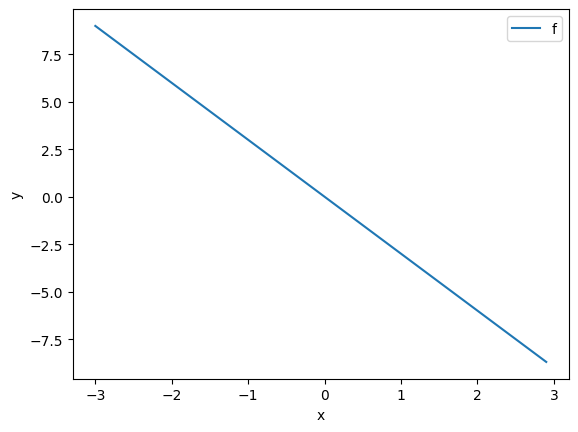

In [4]:
# Plot the line with blue
plt.plot(X.numpy(),f.numpy(),label='f')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

In [5]:
# Add some noise to f(X) and save it in Y
Y = f + 0.1 * torch.randn(X.size())

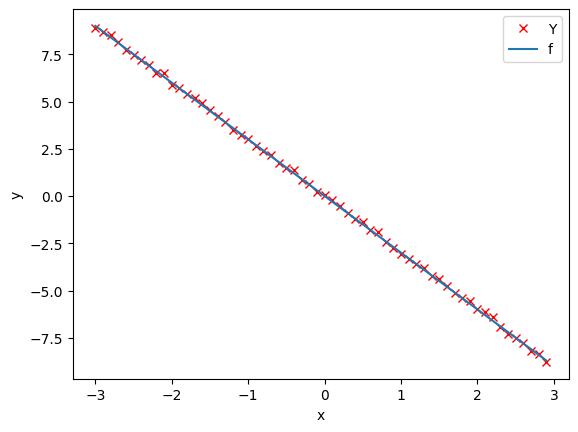

In [6]:
# Plot the Y
plt.plot(X.numpy(),Y.numpy(),'rx',label='Y')
plt.plot(X.numpy(),f.numpy(),label='f')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()

### Create the model and Cost function

In [7]:
# Create forward function for prediction
def forward(x):
    return w * x

In [8]:
# Create the MSE function for evaluate the result
def criterion(yhat,y):
    return torch.mean((yhat - y) ** 2)

In [9]:
# Create Learning rate and an empty list to record the loss for each iteration
lr = 0.1
LOSS = []

In [10]:
# Create a model parameter
w = torch.tensor(-10.0,requires_grad=True)

In [19]:
# Create a plot_diagram object
gradient_plot = plot_diagram(X,Y,w,stop=5)

<class 'numpy.ndarray'>


### Train the Model

In [12]:
# Define a function for train the model
def train_model(iter):
    for epoch in range(iter):
        # make prediction as we learned in the last lab
        yhat = forward(X)

        # calculate the iteration
        loss = criterion(yhat,Y)

        #Plot the diagram
        gradient_plot(yhat,w,loss.item(),epoch)

        # Store the loss into list
        LOSS.append(loss.item())

        # backward pass: compute gradient of the loss
        loss.backward()

        # update parameters
        w.data = w.data - lr * w.grad.data

        # zero the gradients 
        w.grad.data.zero_()

C:\Users\ilyass\AppData\Local\Temp\ipykernel_15472\2252903747.py:32: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  parameter_values_tensor = torch.tensor(self.param_values)
C:\Users\ilyass\AppData\Local\Temp\ipykernel_15472\2252903747.py:33: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:836.)
  loss_function_tensor = torch.tensor(self.Loss_function)


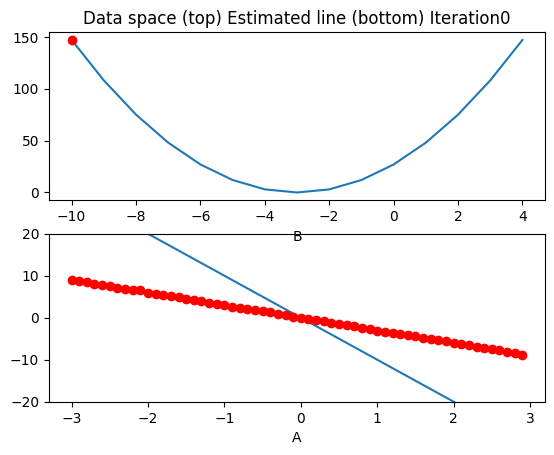

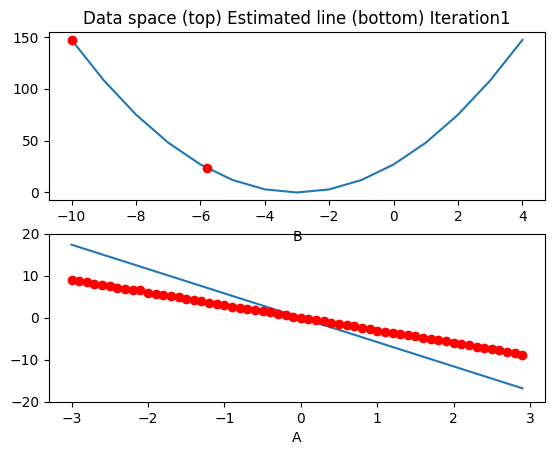

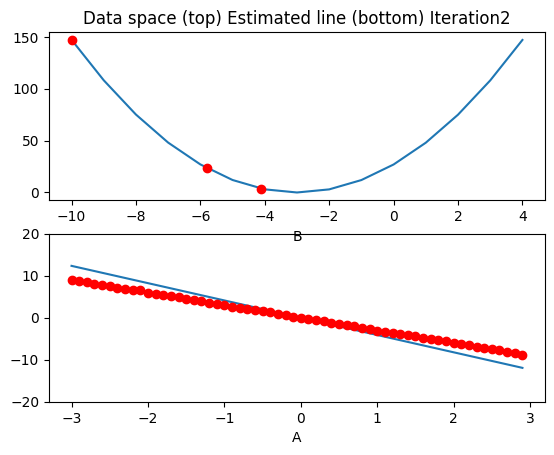

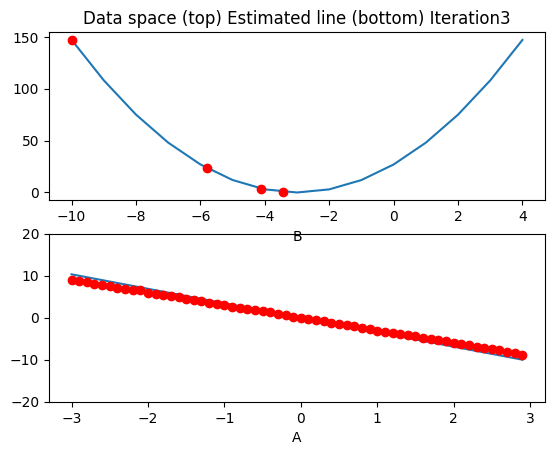

<Figure size 640x480 with 0 Axes>

In [20]:
# Give 4 iterations for training the model here
train_model(4)